<a href="https://colab.research.google.com/github/AthyaNivedita/AIML/blob/main/aiml1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive (1).zip


In [ ]:
import zipfile

zip_file = "archive.zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("archive")

In [ ]:
import os

os.listdir("archive")

['student-lifestyle-and-stress-dataset.csv']

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

In [ ]:
import zipfile

with zipfile.ZipFile("archive.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Extraction Complete")

Extraction Complete


In [ ]:
df = pd.read_csv("dataset/student-lifestyle-and-stress-dataset.csv")

df.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
0,school,6.868702,1.711722,3.176942,NaN,8.0,7.0,2.0,1
1,school,8.519088,3.251084,3.880787,93.978465,6.0,4.0,3.0,1
2,college,4.498770,6.306885,2.936172,64.421253,7.0,1.0,12.0,1
3,school,8.591223,2.384922,5.222832,81.868960,2.0,7.0,7.0,0
4,college,5.329293,9.345179,7.815869,85.847982,5.0,6.0,10.0,1


In [ ]:
df.head()

df.info()

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25500 entries, 0 to 25499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_Type        24248 non-null  object 
 1   Sleep_Hours         24167 non-null  float64
 2   Study_Hours         24223 non-null  float64
 3   Social_Media_Hours  24188 non-null  float64
 4   Attendance          24195 non-null  float64
 5   Exam_Pressure       24230 non-null  float64
 6   Family_Support      24209 non-null  float64
 7   Month               24186 non-null  float64
 8   Stress_Level        25500 non-null  int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 1.8+ MB


,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
count,24167.000000,24223.000000,24188.000000,24195.000000,24230.000000,24209.000000,24186.000000,25500.000000
mean,6.458948,4.696477,3.555614,81.270961,5.369748,5.798298,6.500992,0.299882
std,1.504228,2.240148,1.901528,12.052045,2.394003,2.232371,3.455308,0.458215
min,2.008586,-1.433434,0.000040,-5.000000,1.000000,1.000000,1.000000,0.000000
25%,5.438360,3.078230,2.152249,73.738894,4.000000,4.000000,3.000000,0.000000
50%,6.542566,4.538138,3.500709,81.942959,5.000000,6.000000,6.000000,0.000000
75%,7.531571,6.135670,4.864312,90.106859,7.000000,7.000000,10.000000,1.000000
max,9.997527,22.444460,9.962134,120.000000,10.000000,10.000000,12.000000,1.000000


In [ ]:
print("Rows :",df.shape[0])

print("Columns :",df.shape[1])

print(df.dtypes)

print(df.isnull().sum())

Rows : 25500
Columns : 9
Student_Type           object
Sleep_Hours           float64
Study_Hours           float64
Social_Media_Hours    float64
Attendance            float64
Exam_Pressure         float64
Family_Support        float64
Month                 float64
Stress_Level            int64
dtype: object
Student_Type          1252
Sleep_Hours           1333
Study_Hours           1277
Social_Media_Hours    1312
Attendance            1305
Exam_Pressure         1270
Family_Support        1291
Month                 1314
Stress_Level             0
dtype: int64


In [ ]:
print(df.head())

print(df.tail())

print(df.sample(5))

  Student_Type  Sleep_Hours  Study_Hours  Social_Media_Hours  Attendance  \
0       school     6.868702     1.711722            3.176942         NaN   
1       school     8.519088     3.251084            3.880787   93.978465   
2      college     4.498770     6.306885            2.936172   64.421253   
3       school     8.591223     2.384922            5.222832   81.868960   
4      college     5.329293     9.345179            7.815869   85.847982   

   Exam_Pressure  Family_Support  Month  Stress_Level  
0            8.0             7.0    2.0             1  
1            6.0             4.0    3.0             1  
2            7.0             1.0   12.0             1  
3            2.0             7.0    7.0             0  
4            5.0             6.0   10.0             1  
      Student_Type  Sleep_Hours  Study_Hours  Social_Media_Hours  Attendance  \
25495      college     7.803069     7.328193            2.018277   75.435607   
25496       school     6.734607     2.680109   

In [ ]:
df.isnull().sum()


,0
Student_Type,1252
Sleep_Hours,1333
Study_Hours,1277
Social_Media_Hours,1312
Attendance,1305
Exam_Pressure,1270
Family_Support,1291
Month,1314
Stress_Level,0


In [ ]:
num_cols=df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col]=df[col].fillna(df[col].mean())

    cat_cols=df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col]=df[col].fillna(df[col].mode()[0])

In [ ]:
df.isnull().sum()


,0
Student_Type,0
Sleep_Hours,0
Study_Hours,0
Social_Media_Hours,0
Attendance,0
Exam_Pressure,0
Family_Support,0
Month,0
Stress_Level,0


In [ ]:
print(df.duplicated().sum())

df=df.drop_duplicates()

print(df.shape)

24
(25476, 9)


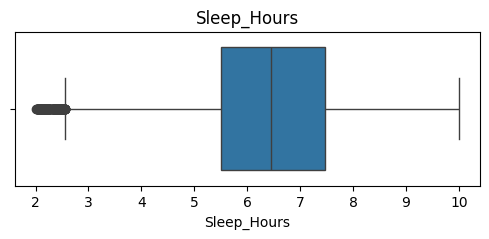

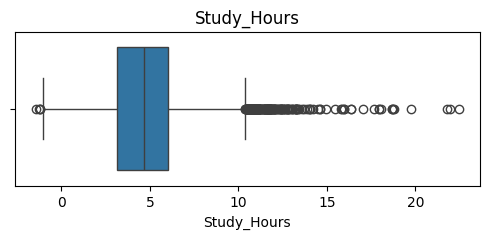

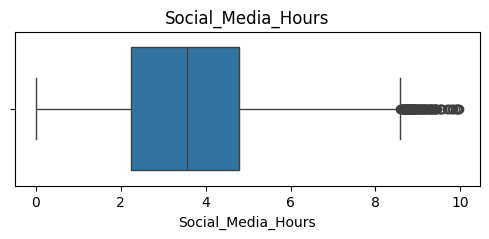

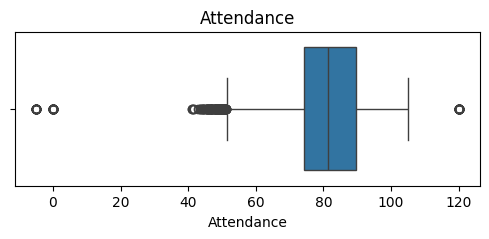

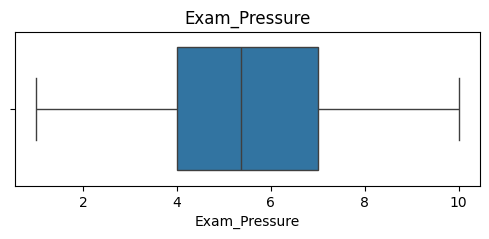

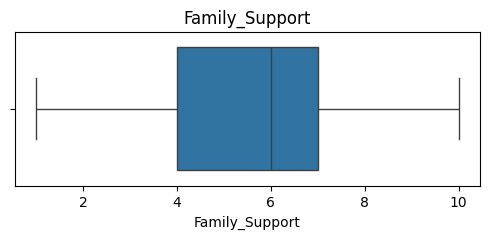

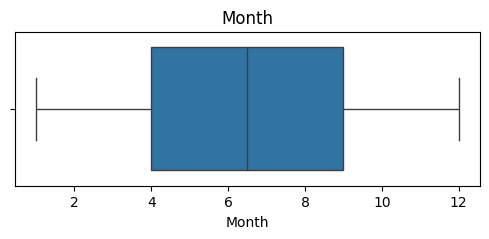

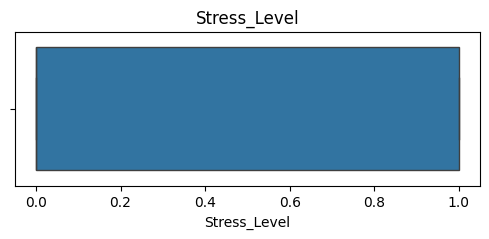

In [ ]:
numeric=df.select_dtypes(include=np.number)

for col in numeric.columns:

    plt.figure(figsize=(6,2))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

In [ ]:
for col in numeric.columns:

    Q1=df[col].quantile(0.25)

    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower=Q1-1.5*IQR

    upper=Q3+1.5*IQR

    df=df[(df[col]>=lower)&(df[col]<=upper)]

In [ ]:
encoder=LabelEncoder()

for col in cat_cols:

    df[col]=encoder.fit_transform(df[col])

In [ ]:
df=pd.get_dummies(df,drop_first=True)

df.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
0,1,6.868702,1.711722,3.176942,81.270961,8.0,7.0,2.0,1
1,1,8.519088,3.251084,3.880787,93.978465,6.0,4.0,3.0,1
2,0,4.498770,6.306885,2.936172,64.421253,7.0,1.0,12.0,1
3,1,8.591223,2.384922,5.222832,81.868960,2.0,7.0,7.0,0
4,0,5.329293,9.345179,7.815869,85.847982,5.0,6.0,10.0,1


In [ ]:
minmax=MinMaxScaler()

scaled=minmax.fit_transform(df)

df_minmax=pd.DataFrame(scaled,columns=df.columns)

df_minmax.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
0,0.5,0.579015,0.241612,0.370436,0.556909,0.777778,0.666667,0.090909,1.0
1,0.5,0.801075,0.377036,0.452507,0.794195,0.555556,0.333333,0.181818,1.0
2,0.0,0.260140,0.645867,0.342362,0.242275,0.666667,0.000000,1.000000,1.0
3,0.5,0.810781,0.300836,0.608993,0.568075,0.111111,0.666667,0.545455,0.0
4,0.0,0.371887,0.913158,0.911349,0.642375,0.444444,0.555556,0.818182,1.0


In [ ]:
standard=StandardScaler()

scaled=standard.fit_transform(df)

df_standard=pd.DataFrame(scaled,columns=df.columns)

df_standard.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
0,0.500666,0.264134,-1.410203,-0.193307,-0.031317,1.127143,0.552205,-1.338965,1.545342
1,0.500666,1.419342,-0.664448,0.194152,1.168815,0.270556,-0.826435,-1.041639,1.545342
2,-0.781879,-1.394731,0.815957,-0.325849,-1.622650,0.698849,-2.205075,1.634302,1.545342
3,0.500666,1.469834,-1.084067,0.932934,0.025160,-1.442619,0.552205,0.147668,-0.647106
4,-0.781879,-0.813396,2.287881,2.360375,0.400950,-0.157738,0.092659,1.039649,1.545342


In [ ]:
corr=df.corr()

corr

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
Student_Type,1.000000,-0.039820,0.058768,-0.008783,0.001615,0.003561,-0.012614,0.000190,0.019406
Sleep_Hours,-0.039820,1.000000,-0.226600,-0.004949,0.002879,0.003287,-0.007354,-0.006254,-0.134385
Study_Hours,0.058768,-0.226600,1.000000,0.013389,0.000805,-0.002991,0.011261,0.002675,0.205177
Social_Media_Hours,-0.008783,-0.004949,0.013389,1.000000,-0.000509,-0.008230,0.006903,-0.004826,0.084205
Attendance,0.001615,0.002879,0.000805,-0.000509,1.000000,0.008368,-0.000919,0.000929,-0.032438
Exam_Pressure,0.003561,0.003287,-0.002991,-0.008230,0.008368,1.000000,-0.004319,0.011701,0.508167
Family_Support,-0.012614,-0.007354,0.011261,0.006903,-0.000919,-0.004319,1.000000,-0.009455,-0.104144
Month,0.000190,-0.006254,0.002675,-0.004826,0.000929,0.011701,-0.009455,1.000000,-0.049129
Stress_Level,0.019406,-0.134385,0.205177,0.084205,-0.032438,0.508167,-0.104144,-0.049129,1.000000


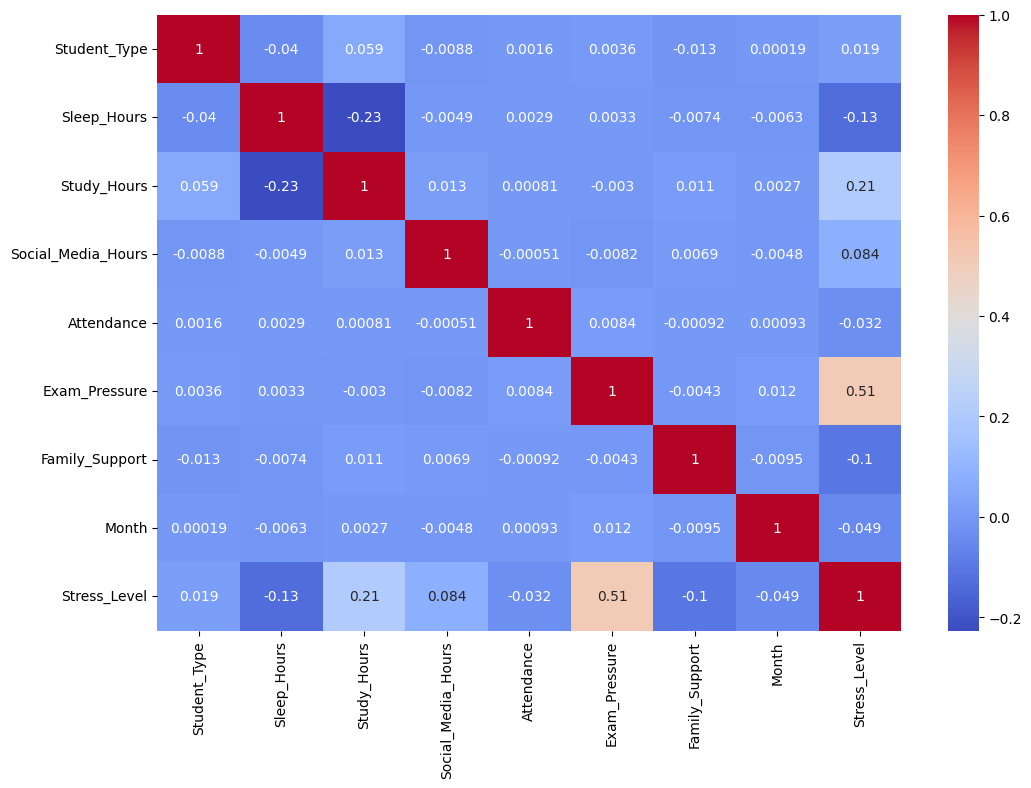

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(corr,annot=True,cmap="coolwarm")

plt.show()


In [ ]:
if len(num_cols)>=2:

    df["New_Feature"]=df[num_cols[0]]+df[num_cols[1]]

df.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level,New_Feature
0,1,6.868702,1.711722,3.176942,81.270961,8.0,7.0,2.0,1,8.580424
1,1,8.519088,3.251084,3.880787,93.978465,6.0,4.0,3.0,1,11.770172
2,0,4.498770,6.306885,2.936172,64.421253,7.0,1.0,12.0,1,10.805656
3,1,8.591223,2.384922,5.222832,81.868960,2.0,7.0,7.0,0,10.976144
4,0,5.329293,9.345179,7.815869,85.847982,5.0,6.0,10.0,1,14.674472


In [ ]:
for col in num_cols:

    df[col]=df[col].astype(float)

df.dtypes

,0
Student_Type,int64
Sleep_Hours,float64
Study_Hours,float64
Social_Media_Hours,float64
Attendance,float64
Exam_Pressure,float64
Family_Support,float64
Month,float64
Stress_Level,float64
New_Feature,float64


In [ ]:
for col in num_cols:

    lower=df[col].quantile(0.01)

    upper=df[col].quantile(0.99)

    df[col]=df[col].clip(lower,upper)

In [ ]:
X=df.drop('Stress_Level',axis=1)
y=df['Stress_Level']

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)

print(X_test.shape)

(19786, 9)
(4947, 9)


In [ ]:
!pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE

smote=SMOTE(random_state=42)

X_train,y_train=smote.fit_resample(X_train,y_train)

print(X_train.shape)

(27960, 9)


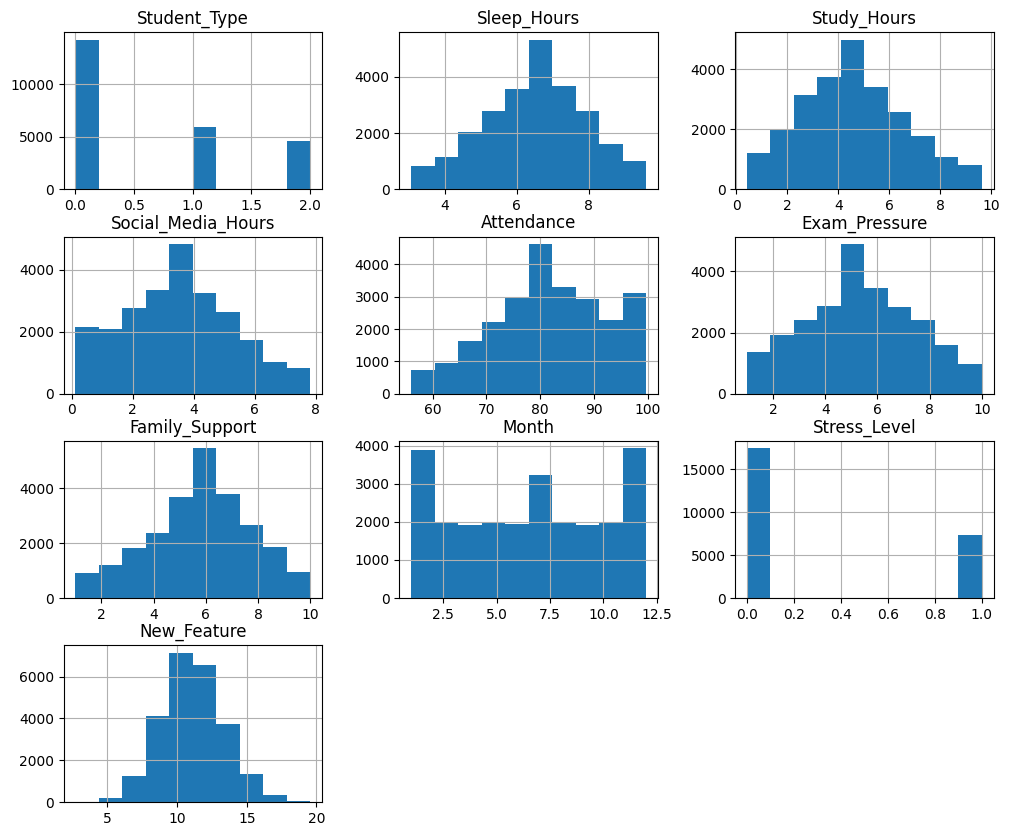

In [ ]:
df.hist(figsize=(12,10))

plt.show()

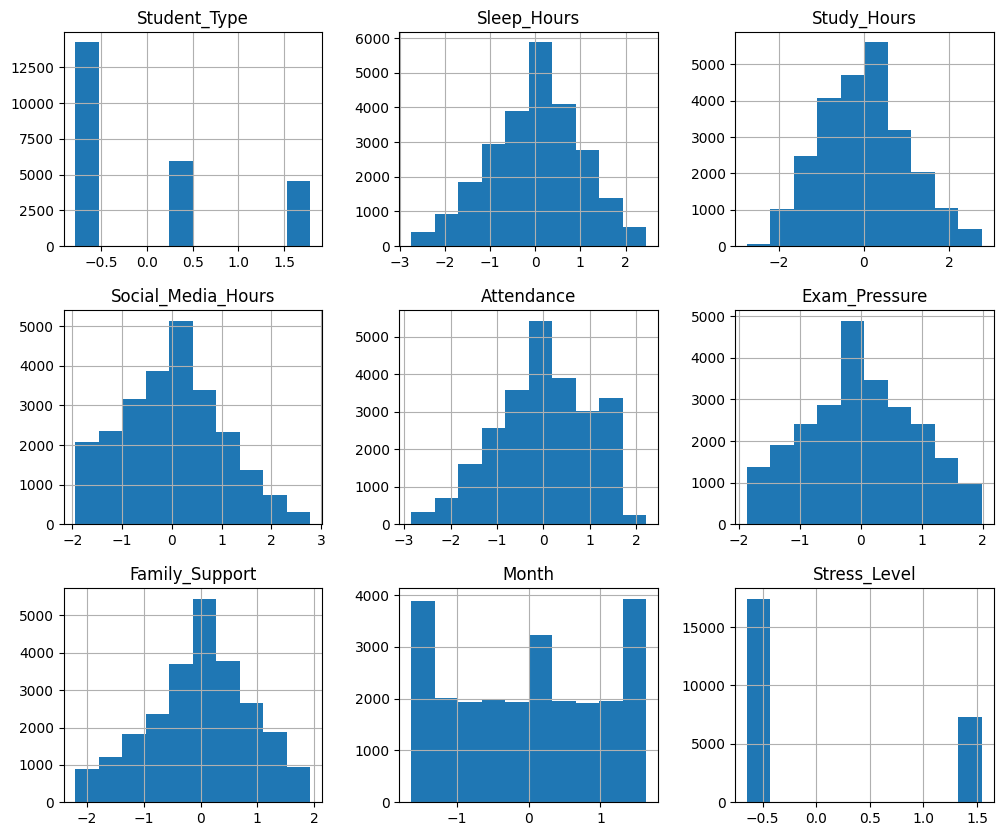

In [ ]:
df_standard.hist(figsize=(12,10))

plt.show()

In [ ]:
original=pd.read_csv("dataset/student-lifestyle-and-stress-dataset.csv")

print("Original Shape")

print(original.shape)

print("Processed Shape")

print(df.shape)

print(original.isnull().sum())

print(df.isnull().sum())

Original Shape
(25500, 9)
Processed Shape
(24733, 10)
Student_Type          1252
Sleep_Hours           1333
Study_Hours           1277
Social_Media_Hours    1312
Attendance            1305
Exam_Pressure         1270
Family_Support        1291
Month                 1314
Stress_Level             0
dtype: int64
Student_Type          0
Sleep_Hours           0
Study_Hours           0
Social_Media_Hours    0
Attendance            0
Exam_Pressure         0
Family_Support        0
Month                 0
Stress_Level          0
New_Feature           0
dtype: int64


In [ ]:
df.to_csv("cleaned_dataset.csv",index=False)

print("Dataset Saved")

Dataset Saved


In [ ]:
from google.colab import files

files.download("cleaned_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>